The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


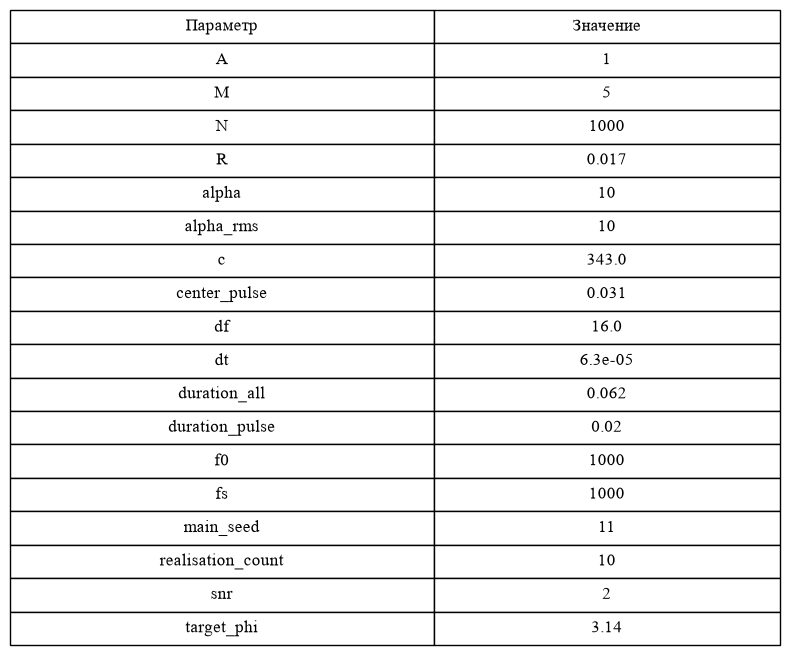

In [14]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import py_files.configs.config as cfg
import py_files.configs.comon as comon
import os
from py_files.plot_scrip import create_and_save_table, create_config_table
from py_files.functions import (
                       get_tau_array,
                       get_covariation_matrix,
                       get_channel_matrix,
                       calculate_barlet_values,
                       get_sin_signal,
                       get_impulse_signal, get_noise, 
                       calculate_noise_level, 
                       calculate_energy,
                       get_avp_signals, 
                       calculate_stiring_matrix, 
                       get_est_phi,
                       calculate_capon_values,
                       calculate_fft, 
                       calculate_f_rms, 
                       spectrum_filtering, 
                       calculate_ifft)

config_parametrs = cfg.init_rng()
path = "images/draft"
os.makedirs(path,exist_ok=True)

create_config_table(config_parametrs)

In [15]:
def test_sinus_freq_rms():
    """Тест сранивает численное вычисление f rms для синусоиду 
    и центральную частоту """

    config_params = cfg.init_rng()
    sin_signal = get_sin_signal(config_params)
    freq_sin_pulse = calculate_fft(sin_signal, config_params["fs"])
    freq_rms = calculate_f_rms(freq_sin_pulse, config_params)


    return freq_rms, config_params["f0"]
a, b = test_sinus_freq_rms()
b/a

np.float64(0.9994137848693005)

In [16]:
def test_lorenth_freq_rms():
    """Тест сранивает численное вычисление f rms для испульса Лоренца от O до T 
    и аналтическую формула на бесконечном интревале времени """

    config_params = cfg.init_rng()
    lorentz_pulse = get_impulse_signal(config_params)
    freq_lorentz_pulse = calculate_fft(lorentz_pulse, config_params["fs"])
    freq_rms = calculate_f_rms(freq_lorentz_pulse, config_params)

    analytical_rms = 1 / (2*np.sqrt(2)*np.pi*config_params["duration_pulse"])
    return freq_rms, analytical_rms

x1, y1 = test_lorenth_freq_rms()
np.abs(y1-x1)



np.float64(0.02833717273133729)